# ME405 Homework 1
## Part 1 Standard Deviations
Hüseyin Kıvanç Küçükevcilioğlu 22202120




First we import numpy as we will use it 


In [1]:
import numpy as np

I need 100 numbers to calculate the standard deviations as it is required by the homework.
I do it by: 

`np.random.random(100)` 

which generates me an array with 100 diffrent random positive floats.


In [2]:
a=np.random.random(100)

Viewing the generated array


In [3]:
a

array([5.63568979e-01, 9.82099485e-01, 5.52728048e-01, 4.58652434e-01,
       5.16287355e-01, 9.92643778e-01, 2.51024908e-01, 6.44830855e-01,
       5.02804870e-01, 9.97446599e-01, 5.72818942e-01, 2.35950397e-01,
       7.46494146e-01, 8.00640783e-01, 2.49881351e-01, 9.39238201e-01,
       2.32530650e-01, 9.00138977e-01, 2.49659067e-02, 8.99154318e-01,
       6.31185280e-01, 6.56995290e-01, 9.39005438e-01, 3.07569838e-01,
       4.07297412e-01, 3.15867875e-01, 3.64017779e-01, 3.09193867e-01,
       5.92351487e-01, 3.76465483e-01, 9.40015318e-02, 6.49396888e-02,
       1.98442233e-01, 1.76887441e-01, 2.27645897e-01, 7.65485589e-01,
       9.14246532e-01, 7.70082055e-01, 5.17320594e-01, 5.80541556e-01,
       8.95077803e-01, 8.93510981e-01, 6.25328576e-01, 2.13331292e-02,
       3.43097931e-04, 4.25979948e-02, 2.01071661e-01, 9.43754090e-01,
       9.28196229e-01, 2.73060643e-01, 4.16786316e-01, 8.66889609e-01,
       4.29162952e-01, 3.40523288e-01, 9.54500483e-02, 5.18078420e-01,
      

Calculating the population and sample deviation using the numpy's already existing tools and then viewing them

In [4]:
normalstd=a.std()

In [5]:
samplestd=a.std(ddof=1)

In [6]:
normalstd

np.float64(0.28991954926734326)

In [7]:
samplestd

np.float64(0.2913801103965862)

Calculating the mean by summing the entire array and dividing by number of the elements which is 100

In [8]:
m=a.sum()/100

In [9]:
d=0

Calculating the variance through and intermediate variable "d" and "c" by summing up the squares of the  diffrences of each element from mean using a for loop


In [10]:
for j in range(100):
    c=(a[j]-m)**2
    d+=c

Dividing square sum by N-1 which is 99 

In [11]:
v=d/99

Then lastly taking the square root of the variance and finding the standard deviation

In [12]:
std=v**0.5

In [13]:
print(std)
print(normalstd)
print(samplestd)

0.2913801103965861
0.28991954926734326
0.2913801103965862


As we can see from the results the standard deviation we found from estimator equations is identical to sample size standard deviation and differs close to 1% from the population size standard deviation. This happens because both our estimator equations and .std(ddof=1) divides the variance by N-1 while population std divides it by N. 

## Part 2 Binning Random Numbers


In [14]:
a=np.random.default_rng(seed=12)

First to generate random numbers i use PCG64 generator with seed as 12.

In [15]:
b=a.random((10000))

Using .random(10000) function i generated 10000 uniform numbers between 0 and 1.

In [16]:
c=a.normal(0.5,0.12, size=(1,10000)) 

Using .normal(0.5,0.12, size=(1,10000) function i generated 10000 normally distrubited numbers between 0 and 1. In the normal function 0.5 represents the mean (as i want them to fall between 0 and 1), 0.12 represents the standard deviation ( i used 0.12 to make sure all of the numbers fall in range of (0,1)).

In [17]:
abin=np.linspace(0,1,11)
unicount=np.zeros(10)
norcount=np.zeros(10)
    

I used .linspace(0,1,11) to generate equally distanced borders for my 10 bins between 0 and 1. Also i generated 2 arrays filled with zeroes to count how many numbers fall between the 11 borders and in the 10 bins i will plot.

In [18]:
for i in range(10):
    unisum=((abin[i]<=b) & (abin[i+1]>b)).sum()
    unicount[i]=unisum
    norsum=((abin[i]<=c) & (abin[i+1]>c)).sum()
    norcount[i]=norsum
    

Here i used a for loop to check how many numbers falls into specific bins. The unisum and norsum variables represent the sum of the boolean values(0,1) of how many numbers falls between the specific edge borders(achivied this using the i variable) and put this sum into the that member of the array(unicount and norcount).

After here the norcount's or unicount's array values represent how many numbers are in the specific bins.

In [19]:
import matplotlib.pyplot as plt


Imported matplot as we will use it to generate bar plots.

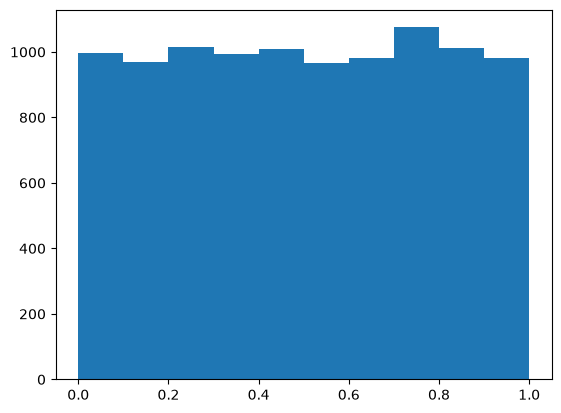

In [20]:
plt.bar(abin[:-1]+0.05, unicount, width=0.1)
plt.show()

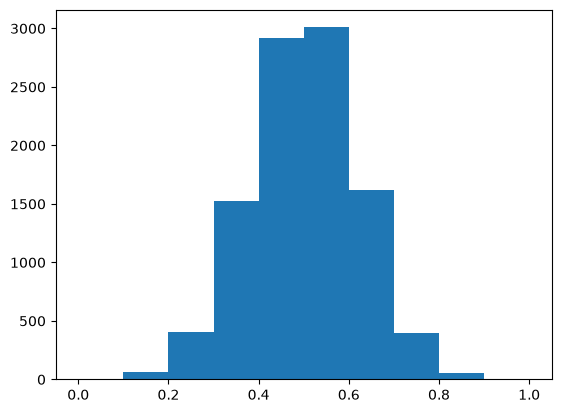

In [21]:
plt.bar(abin[:-1]+0.05, norcount, width=0.1)
plt.show()

I used plt.bar() function to plot my bins. I used abin[:-1]+0.5 as my centers because there are 11 borders and i need 10 centers thus i don't need to use the last border which is 1 and +0.05 to find the centers from the edges.

As we can see the both plot's distrubitions looks like where they came from(whether from uniform or normal) with some errors. These errors happens from as the generated numbers are not perfect and my bins are rather large.

To increase the number of bins i change some values of the variables and run the same code:

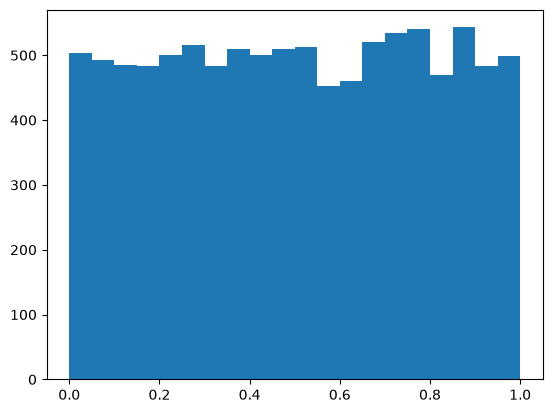

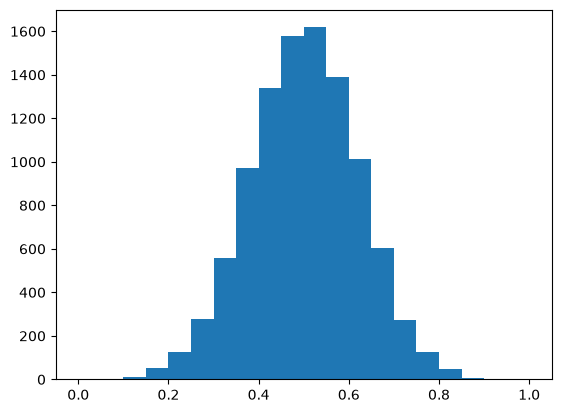

In [22]:
abin=np.linspace(0,1,21)
unicount=np.zeros(20)
norcount=np.zeros(20)
for i in range(20):
    unisum=((abin[i]<=b) & (abin[i+1]>b)).sum()
    unicount[i]=unisum
    norsum=((abin[i]<=c) & (abin[i+1]>c)).sum()
    norcount[i]=norsum
plt.bar(abin[:-1]+0.025, unicount, width=0.05)
plt.show()
plt.bar(abin[:-1]+0.025, norcount, width=0.05)
plt.show()

As we can see if we incrase the bin amount the plots become finer and look more like their distrubitions.

## Part 3 RMSE Function


In [23]:
def rmse(a,b):
    if a.shape == b.shape:
        rmse=((((b-a)**2).sum())/a.size)**(0.5)
        return rmse
    else:
        print("Shapes of the arrays are not the same!")
        return

        

In my root mean squared error(rmse) function firstly i used if statement to check whether shapes of the 2 arrays (y_hat and y) are the same (arguably i could use size command here as well but as you said check for the shapes in the lecture notes i did that.). 

Then if shapes are the same the function does the calculations using the formula given in the lecture notes and returns the rmse. If the shapes doesn't match function prints that.

In [24]:
y_hat= np.array([10,20,30,40])
y= y_hat+ np.ones(4)
rmse(y_hat,y)

np.float64(1.0)

I try my function with 2 arrays differing by an offset of one.

In [25]:
a=np.random.default_rng(seed=13)

To generate 10000 numbers required by the homework i use a generator with 13 as a seed.

In [26]:
b=a.random(10000)

In [27]:
a.shuffle(b)

In [28]:
splits = np.array_split(b,5)

I generate 10000 numbers between 0 and 1 and shuffle them to dissipate any order if there is one and then split them in to 5.

In [29]:
c=0
for part in splits:
    m=part.mean()
    d=np.ones(part.size)
    y_hat=d*m
    c+=1
    rms=rmse(y_hat,part)
    print(c,". parts rmse is",rms)

1 . parts rmse is 0.2885100530482945
2 . parts rmse is 0.288220766323635
3 . parts rmse is 0.2865310096843646
4 . parts rmse is 0.2876272009082736
5 . parts rmse is 0.2896495175313568


I used a for loop to run my rmse function for each part, then print the values i find.

In [30]:
c=0
for part in splits:
    c+=1
    y_hat = part.mean() # 'model' = the mean
    rms = np.sqrt(np.mean((y_hat - part)**2))
    print(c,". parts rmse is",rms,"and std is",np.std(part))
    

    

1 . parts rmse is 0.2885100530482945 and std is 0.2885100530482945
2 . parts rmse is 0.288220766323635 and std is 0.288220766323635
3 . parts rmse is 0.2865310096843646 and std is 0.2865310096843646
4 . parts rmse is 0.2876272009082736 and std is 0.2876272009082736
5 . parts rmse is 0.2896495175313568 and std is 0.2896495175313568


To compare the values i found, i copy and pasted the demo code and also ran the standard deviation command. As we can see all of the three values are identical(my function, demo code and standard deviation). This happens because essentially my function is the same with the demo code and currently as we are using mean as are model when calculating the rmse it becomes the same with standard deviation as it measures the distance from the mean as well.

## Part 4 Data Collection Exercise


In [31]:
import pandas as pd

In [32]:
df = pd.read_csv("btcusd.csv")

In [34]:
df.head()

,open_time,open,high,low,close,volume,close_time,quote_volume,count,taker_buy_volume,taker_buy_quote_volume,ignore
0,1792540800000,82984.7,83194.6,82824.1,82990.9,3022.287,1792544399999,2.510493e+08,88795,1404.849,1.167115e+08,0
1,1792544400000,82990.9,83190.4,82750.4,82965.3,3277.577,1792547999999,2.717753e+08,110225,1622.845,1.345803e+08,0
2,1792548000000,82965.3,83000.0,82689.0,82770.1,3054.494,1792551599999,2.528855e+08,79604,1490.108,1.233590e+08,0
3,1792551600000,82770.0,82837.2,82699.0,82699.0,1317.268,1792555199999,1.090087e+08,44505,725.956,6.007913e+07,0
4,1792555200000,82699.0,82868.6,82698.9,82775.0,2213.307,1792558799999,1.832116e+08,51990,1170.010,9.684784e+07,0


In [39]:
df=df.drop(["close_time","quote_volume","count","taker_buy_quote_volume","ignore"], axis=1)

In [40]:
df["open_time"] = pd.to_datetime(df["open_time"], unit="ms")

In [41]:
df.head()

,open_time,open,high,low,close,volume,taker_buy_volume
0,2026-10-21 00:00:00,82984.7,83194.6,82824.1,82990.9,3022.287,1404.849
1,2026-10-21 01:00:00,82990.9,83190.4,82750.4,82965.3,3277.577,1622.845
2,2026-10-21 02:00:00,82965.3,83000.0,82689.0,82770.1,3054.494,1490.108
3,2026-10-21 03:00:00,82770.0,82837.2,82699.0,82699.0,1317.268,725.956
4,2026-10-21 04:00:00,82699.0,82868.6,82698.9,82775.0,2213.307,1170.010


In [43]:
df=df.set_index("open_time")

In [45]:
df.describe()


,open,high,low,close,volume,taker_buy_volume
count,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
mean,83635.620833,83892.400000,83484.162500,83680.033333,6284.306333,3242.736792
std,767.016687,784.213831,729.218461,758.476039,6157.599327,3373.256063
min,82635.500000,82837.200000,82594.800000,82635.600000,1317.268000,725.956000
25%,82979.850000,83193.550000,82737.550000,82984.500000,2994.981500,1402.657250
50%,83432.700000,83659.800000,83288.500000,83465.700000,3859.466000,1698.798000
75%,84461.275000,84721.925000,84334.725000,84461.225000,7132.670000,3847.177500
max,84800.000000,84875.200000,84605.300000,84800.000000,29130.785000,16005.529000


In [46]:
df.isnull().sum()


open                0
high                0
low                 0
close               0
volume              0
taker_buy_volume    0
dtype: int64

In [48]:
df.nunique()

open                24
high                24
low                 23
close               24
volume              24
taker_buy_volume    24
dtype: int64

In [49]:
df.drop_duplicates()

,open,high,low,close,volume,taker_buy_volume
open_time,,,,,,
2026-10-21 00:00:00,82984.7,83194.6,82824.1,82990.9,3022.287,1404.849
2026-10-21 01:00:00,82990.9,83190.4,82750.4,82965.3,3277.577,1622.845
2026-10-21 02:00:00,82965.3,83000.0,82689.0,82770.1,3054.494,1490.108
2026-10-21 03:00:00,82770.0,82837.2,82699.0,82699.0,1317.268,725.956
2026-10-21 04:00:00,82699.0,82868.6,82698.9,82775.0,2213.307,1170.010
2026-10-21 05:00:00,82774.9,82929.1,82594.8,82635.6,1989.262,965.439
2026-10-21 06:00:00,82635.5,82881.9,82606.5,82763.9,1644.705,915.306
2026-10-21 07:00:00,82763.8,83233.4,82697.5,83130.2,6477.380,3822.832
2026-10-21 08:00:00,83130.2,83686.2,83065.0,83213.6,8781.473,4912.779
